## TOC:
* [Imports and Variables](#bullet1)
* [Environment](#bullet2)
* [PPO Configs & Training](#bullet3)

## Abbreviations

CGM = Continuous Glucose Measurement (mg/dL)

## Imports and Variables <a class="anchor" id="bullet1"></a>

In [28]:
# --- Imports ---
from pathlib import Path
from datetime import datetime, timedelta

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from simglucose.envs import T1DSimGymnaisumEnv
from simglucose.simulation.scenario import CustomScenario

from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.vec_env import DummyVecEnv, VecFrameStack
from stable_baselines3.common.utils import set_random_seed
from stable_baselines3.common.callbacks import CheckpointCallback

In [29]:
# --- Variables ---

MODEL_DIR = Path("models")
RESULT_DIR = Path("results")

MODEL_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

TRAIN_PATIENT = "adolescent#002"
TEST_PATIENTS = ["adolescent#001", "adolescent#003", "adult#001", "child#001"]

TRAIN_SEEDS = [1, 2, 3]
EVAL_SEEDS = [101, 102, 103]
VALIDATION_SEEDS = [101, 102, 103]
N_STACK = 40

# Gebruik eerst 15.000 om de code te testen.
# Verhoog daarna voor het echte experiment.
TOTAL_TIMESTEPS_TEST = 100_000  # 15_000
TOTAL_TIMESTEPS_FINAL = 100_000
TOTAL_TIMESTEPS = TOTAL_TIMESTEPS_TEST
CHECKPOINT_FREQUENCY = 5000

# Ongeveer 24 uur bij een sampletijd van 3 minuten
EVAL_STEPS = 480

## Functions <a class="anchor" id="bulletFunctions"></a>

In [ ]:
# Plot functions
def plot_ppo_trajectory(trajectory, title):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharex=True)
    axes[0].plot(trajectory["step"], trajectory["bg"], color="tab:blue", label="CGM")
    axes[0].axhspan(70, 180, color="green", alpha=0.12, label="Target range")
    axes[0].axhline(70, color="red", linestyle="--")
    axes[0].axhline(180, color="orange", linestyle="--")

    meal_steps = trajectory.loc[trajectory["meal"] > 0, "step"]

    for meal_step in meal_steps:
        axes[0].axvline(meal_step, color="purple", linestyle=":", alpha=0.4)

    axes[0].set_ylabel("CGM [mg/dL]")
    axes[0].set_title(title)
    axes[0].legend()
    axes[0].grid()

    axes[1].plot(trajectory["step"], trajectory["insulin_action"], color="tab:orange")
    axes[1].set_ylabel("Basal action")
    axes[1].grid()

    axes[2].plot(trajectory["step"], trajectory["reward"], color="tab:green")
    axes[2].axhline(0, color="black", linestyle="--")
    axes[2].set_ylabel("Reward")
    axes[2].set_xlabel("Simulation step")
    axes[2].grid()

    plt.tight_layout()
    plt.show()

def plot_ppo_training_progress(hyperparameter_df):

    # Gemiddelde over de verschillende evaluation seeds
    summary = hyperparameter_df.groupby(
        ["config_id", "train_seed", "training_steps"], as_index=False
    ).agg(
        mean_tir=("tir_70_180", "mean"),
        std_tir=("tir_70_180", "std"),
        mean_tbr70=("tbr_below_70", "mean"),
        mean_tar180=("tar_above_180", "mean"),
        mean_bg=("mean_bg", "mean"),
        mean_insulin=("mean_insulin_action", "mean"),
        mean_number_of_steps=("number_of_steps", "mean"),
    )

    configs = sorted(summary["config_id"].unique())

    # Een aparte figuur per PPO-configuratie
    for config in configs:
        config_df = summary[summary["config_id"] == config]
        fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
        train_seeds = sorted(config_df["train_seed"].unique())

        for train_seed in train_seeds:

            seed_df = config_df[config_df["train_seed"] == train_seed].sort_values(
                "training_steps"
            )

            # TIR
            axes[0].plot(
                seed_df["training_steps"],
                seed_df["mean_tir"],
                marker="o",
                label=f"Train seed {train_seed}",
            )

            # TBR en TAR
            axes[1].plot(
                seed_df["training_steps"],
                seed_df["mean_tbr70"],
                marker="o",
                label=f"TBR seed {train_seed}",
            )

            axes[1].plot(
                seed_df["training_steps"],
                seed_df["mean_tar180"],
                marker="x",
                linestyle="--",
                label=f"TAR seed {train_seed}",
            )

            # Mean CGM
            axes[2].plot(
                seed_df["training_steps"],
                seed_df["mean_bg"],
                marker="o",
                label=f"Train seed {train_seed}",
            )

        # TIR
        axes[0].set_title(f"{config}: performance during training")
        axes[0].set_ylabel("Mean TIR [%]")
        axes[0].set_ylim(0, 100)
        axes[0].grid(alpha=0.3)
        axes[0].legend()

        # TBR / TAR
        axes[1].set_ylabel("Time [%]")
        axes[1].set_ylim(0, 100)
        axes[1].grid(alpha=0.3)
        axes[1].legend()

        # CGM
        axes[2].axhspan(70, 180, color="green", alpha=0.1)
        axes[2].axhline(70, color="red", linestyle="--")
        axes[2].axhline(180, color="orange", linestyle="--")
        axes[2].set_ylabel("Mean CGM [mg/dL]")
        axes[2].set_xlabel("Training steps")
        axes[2].grid(alpha=0.3)
        axes[2].legend()

        plt.tight_layout()
        plt.show()


def plot_all_ppo_tir(hyperparameter_df):
    summary = hyperparameter_df.groupby(
        ["config_id", "train_seed", "training_steps"], as_index=False).agg(mean_tir=("tir_70_180", "mean"))

    configs = sorted(summary["config_id"].unique())
    fig, axes = plt.subplots(1, len(configs), figsize=(6 * len(configs), 5), sharey=True)

    if len(configs) == 1:
        axes = [axes]

    for ax, config in zip(axes, configs):
        config_df = summary[summary["config_id"] == config]

        for train_seed in sorted(config_df["train_seed"].unique()):
            seed_df = config_df[config_df["train_seed"] == train_seed].sort_values(
                "training_steps")

            ax.plot(
                seed_df["training_steps"],
                seed_df["mean_tir"],
                marker="o",
                label=f"Seed {train_seed}",)
        ax.set_title(config)
        ax.set_xlabel("Training steps")
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.3)
        ax.legend()

    axes[0].set_ylabel("Mean TIR [%]")

    plt.suptitle("PPO validation performance during training")

    plt.tight_layout()
    plt.show()


def plot_control_behavior(results_df):
    configs = results_df["config_id"].unique()
    fig, ax = plt.subplots(figsize=(10, 7))

    # Verschillende labelposities
    offsets = [
        (7, 7),
        (7, -15),
        (-55, 7),
        (-55, -15),
        (15, 15),
        (-65, 15),
    ]

    for config in configs:
        subset = results_df[results_df["config_id"] == config]
        ax.scatter(subset["mean_insulin_action"], subset["mean_bg"], s=70, alpha=0.7, label=config,)

        # Label toevoegen aan iedere punt
        for i, (_, row) in enumerate(subset.iterrows()):
            offset = offsets[i % len(offsets)]

            ax.annotate(
                f'{int(row["number_of_steps"])}',
                xy=(row["mean_insulin_action"], row["mean_bg"]),
                xytext=offset,
                textcoords="offset points",
                fontsize=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, edgecolor="none"), arrowprops=dict(arrowstyle="-", color="gray", alpha=0.5),)

    ax.axhspan(70, 180, color="green", alpha=0.1)
    ax.axhline(180, color="orange", linestyle="--")
    ax.axhline(70, color="red", linestyle="--")

    ax.set_xlabel("Mean basal insulin action")
    ax.set_ylabel("Mean CGM [mg/dL]")
    ax.set_title("Insulin action versus glucose control")

    ax.legend()

    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

def plot_hyperparameter_results(summary_df):
    plot_df = summary_df.copy()

    x = np.arange(len(plot_df))
    width = 0.25

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.bar(x - width, plot_df["mean_tir"], width, label="TIR 70–180")
    ax.bar(x, plot_df["mean_tbr70"], width, label="TBR <70")
    ax.bar(x + width, plot_df["mean_tar180"], width, label="TAR >180")

    ax.set_xticks(x)
    ax.set_xticklabels(plot_df["config_id"])

    ax.set_ylabel("Time [%]")
    ax.set_xlabel("PPO configuration")
    ax.set_title("PPO hyperparameter comparison on adolescent#002")

    ax.set_ylim(0, 100)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()
    
def plot_scenario_comparison(comparison_df):
    patients = comparison_df["patient"].tolist()

    x = np.arange(len(patients))
    width = 0.35

    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    axes[0].bar(x - width / 2, comparison_df["standard_tir"], width, label="Standard")
    axes[0].bar(x + width / 2, comparison_df["stress_tir"], width, label="High-carb")
    axes[0].set_ylabel("TIR [%]")
    axes[0].set_title("Time in Range under standard and high-carb conditions")
    axes[0].set_ylim(0, 100)
    axes[0].legend()
    axes[0].grid(axis="y", alpha=0.3)

    axes[1].bar(x - width / 2, comparison_df["standard_tar250"], width, label="Standard")
    axes[1].bar(x + width / 2, comparison_df["stress_tar250"], width, label="High-carb")
    axes[1].set_ylabel("Time Above 250 [%]")
    axes[1].set_title("Severe hyperglycemia under standard " "and high-carb conditions")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(patients, rotation=45, ha="right")
    axes[1].legend()
    axes[1].grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

def plot_final_summary(final_summary):
    df = final_summary.copy()
    scenarios = df["scenario"].unique()

    for scenario in scenarios:
        scenario_df = df[df["scenario"] == scenario].copy()

        patients = scenario_df["patient"].unique()
        controllers = scenario_df["controller"].unique()

        x = np.arange(len(patients))
        width = 0.35

        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        # --------------------------------------------------
        # 1. Time in Range
        # --------------------------------------------------

        for i, controller in enumerate(controllers):

            subset = (
                scenario_df[scenario_df["controller"] == controller]
                .set_index("patient")
                .reindex(patients)
            )

            offset = (i - (len(controllers) - 1) / 2) * width

            axes[0, 0].bar(x + offset, subset["mean_tir"], width, label=controller)

        axes[0, 0].set_title("Time in Range")
        axes[0, 0].set_ylabel("TIR 70-180 mg/dL [%]")
        axes[0, 0].set_ylim(0, 100)
        axes[0, 0].grid(axis="y", alpha=0.3)
        axes[0, 0].legend()

        # --------------------------------------------------
        # 2. Time Below Range
        # --------------------------------------------------

        for i, controller in enumerate(controllers):

            subset = (
                scenario_df[scenario_df["controller"] == controller]
                .set_index("patient")
                .reindex(patients)
            )

            offset = (i - (len(controllers) - 1) / 2) * width

            axes[0, 1].bar(x + offset, subset["mean_tbr70"], width, label=controller)

        axes[0, 1].set_title("Hypoglycemia")
        axes[0, 1].set_ylabel("TBR <70 mg/dL [%]")
        axes[0, 1].grid(axis="y", alpha=0.3)
        axes[0, 1].legend()

        # --------------------------------------------------
        # 3. Time Above Range
        # --------------------------------------------------

        for i, controller in enumerate(controllers):

            subset = (
                scenario_df[scenario_df["controller"] == controller]
                .set_index("patient")
                .reindex(patients)
            )

            offset = (i - (len(controllers) - 1) / 2) * width

            axes[1, 0].bar(x + offset, subset["mean_tar180"], width, label=controller)

        axes[1, 0].set_title("Hyperglycemia")
        axes[1, 0].set_ylabel("TAR >180 mg/dL [%]")
        axes[1, 0].grid(axis="y", alpha=0.3)
        axes[1, 0].legend()

        # --------------------------------------------------
        # 4. Mean CGM
        # --------------------------------------------------

        for i, controller in enumerate(controllers):

            subset = (
                scenario_df[scenario_df["controller"] == controller]
                .set_index("patient")
                .reindex(patients)
            )

            offset = (i - (len(controllers) - 1) / 2) * width

            axes[1, 1].bar(x + offset, subset["mean_bg"], width, label=controller)

        # Target range aangeven
        axes[1, 1].axhspan(70, 180, color="green", alpha=0.1)

        axes[1, 1].axhline(70, color="red", linestyle="--")

        axes[1, 1].axhline(180, color="orange", linestyle="--")

        axes[1, 1].set_title("Mean CGM")
        axes[1, 1].set_ylabel("Mean CGM [mg/dL]")
        axes[1, 1].grid(axis="y", alpha=0.3)
        axes[1, 1].legend()

        # --------------------------------------------------
        # X labels
        # --------------------------------------------------

        for ax in axes.flat:

            ax.set_xticks(x)

            ax.set_xticklabels(patients, rotation=45, ha="right")

        plt.suptitle(f"PPO versus BBController: {scenario}", fontsize=16)

        plt.tight_layout()
        plt.show()

In [31]:
def train_ppo_with_checkpoints(
    patient_name, config, train_seed, total_timesteps=TOTAL_TIMESTEPS
):
    train_env = make_vec_env(patient_name=patient_name, seed=train_seed)

    model = PPO(
        policy="MlpPolicy",
        env=train_env,
        learning_rate=config["learning_rate"],
        n_steps=config["n_steps"],
        batch_size=config["batch_size"],
        gamma=config["gamma"],
        gae_lambda=0.95,
        clip_range=0.20,
        ent_coef=0.0,
        policy_kwargs={"net_arch": [64, 64]},
        verbose=0,
        seed=train_seed,
        device="cpu",
    )

    checkpoint_dir = MODEL_DIR / f"checkpoints_{config['config_id']}_seed{train_seed}"

    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_callback = CheckpointCallback(
        save_freq=CHECKPOINT_FREQUENCY,
        save_path=str(checkpoint_dir),
        name_prefix=(f"{config['config_id']}_" f"{patient_name}_" f"seed{train_seed}"),
    )

    model.learn(
        total_timesteps=total_timesteps, callback=checkpoint_callback, progress_bar=True
    )

    # final_model_path = checkpoint_dir / (
    #     f"{config['config_id']}_" f"{patient_name}_" f"seed{train_seed}_final"
    # )

    # model.save(str(final_model_path))

    train_env.close()

    return checkpoint_dir


def get_training_steps(checkpoint_file):
    filename = checkpoint_file.stem

    parts = filename.split("_")

    for i, part in enumerate(parts):
        if part == "steps" and i > 0:
            try:
                return int(parts[i - 1])
            except ValueError:
                pass

    return np.nan


def evaluate_checkpoints(checkpoint_dir, patient_name, validation_seeds):
    results = []
    checkpoint_files = list(checkpoint_dir.glob("*.zip"))
    checkpoint_files = [file for file in checkpoint_files if "steps" in file.stem]
    checkpoint_files = sorted(checkpoint_files, key=get_training_steps)

    for checkpoint_file in checkpoint_files:

        training_steps = get_training_steps(checkpoint_file)

        print()
        print("Evaluating checkpoint:", training_steps, "training steps")

        for eval_seed in validation_seeds:

            print("Validation seed:", eval_seed)

            metrics, trajectory = evaluate_ppo(
                model_path=str(checkpoint_file),
                patient_name=patient_name,
                eval_seed=eval_seed,
                n_steps=EVAL_STEPS,
            )

            results.append(
                {
                    "checkpoint": str(checkpoint_file),
                    "training_steps": training_steps,
                    "eval_seed": eval_seed,
                    **metrics,
                }
            )

    checkpoint_df = pd.DataFrame(results)

    return checkpoint_df


def summarize_checkpoints(checkpoint_df):

    checkpoint_summary = (
        checkpoint_df.groupby(["checkpoint", "training_steps"], as_index=False)
        .agg(
            mean_tir=("tir_70_180", "mean"),
            std_tir=("tir_70_180", "std"),
            mean_tbr70=("tbr_below_70", "mean"),
            mean_tbr54=("tbr_below_54", "mean"),
            mean_tar180=("tar_above_180", "mean"),
            mean_tar250=("tar_above_250", "mean"),
            mean_bg=("mean_bg", "mean"),
            mean_bg_sd=("std_bg", "mean"),
            number_of_steps=("number_of_steps", "mean"),
        )
        .sort_values("training_steps")
        .reset_index(drop=True)
    )

    return checkpoint_summary


def select_best_checkpoint(checkpoint_summary):
    best_index = checkpoint_summary["mean_tir"].idxmax()
    best_checkpoint = checkpoint_summary.loc[best_index]

    return best_checkpoint


def plot_checkpoint_selection(checkpoint_summary):
    df = checkpoint_summary.sort_values("training_steps")

    fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)

    axes[0].plot(df["training_steps"], df["mean_tir"], marker="o", label="Mean TIR")
    axes[0].fill_between(
        df["training_steps"],
        df["mean_tir"] - df["std_tir"],
        df["mean_tir"] + df["std_tir"],
        alpha=0.2,
    )

    axes[0].set_ylabel("TIR [%]")
    axes[0].set_ylim(0, 100)
    axes[0].set_title("Validation performance during PPO training")
    axes[0].grid(alpha=0.3)
    axes[0].legend()
    axes[1].plot(df["training_steps"], df["mean_tbr70"], marker="o", label="TBR <70")
    axes[1].plot(df["training_steps"], df["mean_tar180"], marker="o", label="TAR >180")
    axes[1].set_ylabel("Time [%]")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    axes[2].plot(df["training_steps"], df["mean_bg"], marker="o", label="Mean CGM")
    axes[2].axhspan(70, 180, color="green", alpha=0.1)
    axes[2].axhline(70, color="red", linestyle="--")
    axes[2].axhline(180, color="orange", linestyle="--")
    axes[2].set_xlabel("Training timesteps")
    axes[2].set_ylabel("Mean CGM [mg/dL]")
    axes[2].grid(alpha=0.3)
    axes[2].legend()

    plt.tight_layout()
    plt.show()


In [32]:
def evaluate_checkpoints(
    checkpoint_dir,
    patient_name,
    validation_seeds):
    results = []
    checkpoint_files = sorted(checkpoint_dir.glob("*.zip"))

    for checkpoint_file in checkpoint_files:
        # Stable Baselines checkpoint naam*eindigt bijvoorbeeld:
        # ..*_15000_steps.zip
        filename = checkpoint_file.stem

        try:
            training_steps = int(filename.split("_")[-2])
        except ValueError:
            training_steps = np.nan

        print(
           f"Evaluating checkpoint: "
           f"{training_steps} training steps"
        )

        for eval_seed in validation_seeds:

            metrics, _ = evaluate_ppo(model_path=str(checkpoint_file), patient_name=patient_name, eval_seed=eval_seed, n_steps=EVAL_STEPS)

            results.append({
              "checkpoint": str(checkpoint_file),
                "training_steps": training_steps,
               "eval_seed": eval_seed,
               **metrics})

    return pd.DataFrame(results)

## Environment <a class="anchor" id="bullet2"></a>

In [33]:
def custom_reward(bg_last_hour):
    bg = float(bg_last_hour[-1])

    # Ernstige hypoglykemie
    if bg < 54:
        return -10.0 - 0.10 * (54.0 - bg)

    # Hypoglykemie
    if bg < 70:
        return -2.0 - 0.05 * (70.0 - bg)

    if bg <= 94:
        return 1.0 + (0.01 * (bg))

    if bg <= 156:
        return 2.0 + (0.05 * (bg))

    # Time in Range
    if bg <= 180:
        return 1.0 + (0.01 * (bg))

    # Hyperglykemie
    if bg <= 250:
        return -1.0 - 0.01 * (bg - 180.0)

    # Ernstige hyperglykemie
    return -3.0 - 0.02 * (bg - 250.0)

In [34]:
class SimglucoseActionWrapper(gym.Wrapper):
    def reset(self, *, seed=None, options=None):
        observation, info = self.env.reset(seed=seed, options=options)
        observation = np.asarray(observation, dtype=np.float32)
        return observation, info

    def step(self, action):
        action_array = np.asarray(action, dtype=np.float32)
        action_scalar = float(action_array.reshape(-1)[0])
        observation, reward, terminated, truncated, info = self.env.step(action_scalar)
        observation = np.asarray(observation, dtype=np.float32)

        return (observation, float(reward), bool(terminated), bool(truncated), info)

In [35]:
def make_single_env(patient_name, seed, custom_scenario=None):
    base_env = T1DSimGymnaisumEnv(patient_name=patient_name, custom_scenario=custom_scenario, reward_fun=custom_reward, seed=seed)
    env = SimglucoseActionWrapper(base_env)
    env = Monitor(env)

    return env

def make_vec_env(patient_name, seed, custom_scenario=None, n_stack=N_STACK):
    set_random_seed(seed)

    def env_factory():
        return make_single_env(patient_name=patient_name, seed=seed, custom_scenario=custom_scenario)

    vec_env = DummyVecEnv([env_factory])
    vec_env = VecFrameStack(vec_env, n_stack=n_stack)

    return vec_env

In [36]:
test_env = make_single_env(patient_name=TRAIN_PATIENT, seed=123)

check_env(test_env, warn=True)

print("Observation space:", test_env.observation_space)
print("Action space:", test_env.action_space)

test_env.close()

Observation space: Box(0.0, 1000.0, (1,), float32)
Action space: Box(0.0, 30.0, (1,), float32)


C:\Users\310271491\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\stable_baselines3\common\env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


## PPO Configs <a class="anchor" id="bullet3"></a>

In [37]:
PPO_CONFIGS = [
    {
        "config_id": "PPO_A",
        "learning_rate": 3e-4,
        "n_steps": 512,
        "batch_size": 64,
        "gamma": 0.99
    },
    {
        "config_id": "PPO_B",
        "learning_rate": 1e-4,
        "n_steps": 512,
        "batch_size": 64,
        "gamma": 0.99
    },
    {
        "config_id": "PPO_C",
        "learning_rate": 3e-4,
        "n_steps": 1024,
        "batch_size": 64,
        "gamma": 0.995
    }
]

for config in PPO_CONFIGS:
    assert config["n_steps"] % config["batch_size"] == 0

In [38]:
def train_ppo_model(patient_name, config, train_seed, total_timesteps):
    train_env = make_vec_env(patient_name=patient_name, seed=train_seed)

    model = PPO(
        policy="MlpPolicy",
        env=train_env,
        learning_rate=config["learning_rate"],
        n_steps=config["n_steps"],
        batch_size=config["batch_size"],
        gamma=config["gamma"],
        gae_lambda=0.95,
        clip_range=0.20,
        ent_coef=0.0,
        policy_kwargs={"net_arch": [64, 64]},
        verbose=0,
        seed=train_seed,
        device="cpu",
    )

    checkpoint_dir = (
        MODEL_DIR /
        f"checkpoints_{config['config_id']}_seed{train_seed}"
    )

    checkpoint_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_callback = CheckpointCallback(
        save_freq=5000,
        save_path=str(checkpoint_dir),
        name_prefix=(
            f"{config['config_id']}_"
            f"{patient_name}_"
            f"seed{train_seed}"
        )
    )

    model.learn(total_timesteps=total_timesteps, callback=checkpoint_callback, progress_bar=True)
    #model_path = MODEL_DIR / (f"{config['config_id']}_" f"{patient_name}_" f"seed{train_seed}")
    #model.save(model_path)
    train_env.close()

    return str(model_path)

## PPO Training or Loading <a class="anchor" id="bullet4"></a>

In [ ]:
def get_training_steps(model_path):
    filename = model_path.stem
    parts = filename.split("_")

    for i, part in enumerate(parts):
        if part == "steps" and i > 0:
            return int(parts[i - 1])

    return None

trained_models = []

## -------------------------------------------------------------------
## Switch for loading existing Policy or retraining the Policy
## -------------------------------------------------------------------
load_existing_models = True

if load_existing_models:
    trained_models_df = pd.read_csv(RESULT_DIR / "trained_models.csv")
    trained_models = trained_models_df.to_dict(orient="records")
else:  # Train new Models
    for config in PPO_CONFIGS:
        for train_seed in TRAIN_SEEDS:
            print(
                f"Training {config['config_id']} | "
                f"patient={TRAIN_PATIENT} | "
                f"seed={train_seed}")

            checkpoint_dir = train_ppo_with_checkpoints(
                patient_name=TRAIN_PATIENT,
                config=config,
                train_seed=train_seed,
                total_timesteps=TOTAL_TIMESTEPS,)
            
            checkpoint_files = list(checkpoint_dir.glob("*_steps.zip"))
            checkpoint_files = sorted(checkpoint_files, key=get_training_steps)

            for model_path in checkpoint_files:
                training_steps = get_training_steps(model_path)

                trained_models.append({
                        "config_id": config["config_id"],
                        "patient": TRAIN_PATIENT,
                        "train_seed": train_seed,
                        "training_steps": training_steps,
                        "model_path": str(model_path),
                    })

    trained_models_df = pd.DataFrame(trained_models)
    trained_models_df.to_csv(RESULT_DIR / "trained_models.csv", index=False)

    print(trained_models_df)

In [40]:
def calculate_metrics(glucose, insulin, rewards, terminated_early):
    glucose = np.asarray(glucose, dtype=float)
    insulin = np.asarray(insulin, dtype=float)
    rewards = np.asarray(rewards, dtype=float)

    if len(glucose) == 0:
        raise ValueError("Er zijn geen glucosemetingen verzameld.")

    return {
        "number_of_steps": len(glucose),
        "mean_bg": float(np.mean(glucose)),
        "std_bg": float(np.std(glucose)),
        "min_bg": float(np.min(glucose)),
        "max_bg": float(np.max(glucose)),
        "tir_70_180": float(100.0 * np.mean((glucose >= 70.0) & (glucose <= 180.0))),
        "tbr_below_70": float(100.0 * np.mean(glucose < 70.0)),
        "tbr_below_54": float(100.0 * np.mean(glucose < 54.0)),
        "tar_above_180": float(100.0 * np.mean(glucose > 180.0)),
        "tar_above_250": float(100.0 * np.mean(glucose > 250.0)),
        "mean_reward": float(np.mean(rewards)),
        "total_reward": float(np.sum(rewards)),
        "mean_insulin_action": float(np.mean(insulin)),
        "sum_insulin_actions": float(np.sum(insulin)),
        "terminated_early": bool(terminated_early),
    }

## PPO Eval Function <a class="anchor" id="bullet5"></a>

In [41]:
def evaluate_ppo(model_path, patient_name, eval_seed, training_steps, custom_scenario=None, n_steps=EVAL_STEPS):
    eval_env = make_vec_env(patient_name=patient_name, seed=eval_seed, custom_scenario=custom_scenario)
    model = PPO.load(model_path, env=eval_env, device="cpu")

    observation = eval_env.reset()

    glucose_values = []
    insulin_values = []
    reward_values = []
    meal_values = []

    terminated_early = False

    for step in range(n_steps):
        action, _ = model.predict(observation, deterministic=True)
        next_observation, reward, done, info = eval_env.step(action)
        insulin = float(np.asarray(action).reshape(-1)[0])
        reward_value = float(reward[0])
        info_dict = info[0] if len(info) > 0 else {}

        if done[0]:
            terminated_early = step < n_steps - 1
            terminal_observation = info_dict.get("terminal_observation")

            if terminal_observation is not None:
                terminal_observation = np.asarray(terminal_observation)
                bg = float(terminal_observation.reshape(-1)[-1])
            else:
                bg = float(next_observation[0, -1])
        else:
            bg = float(next_observation[0, -1])

        meal = float(info_dict.get("meal", 0.0))

        glucose_values.append(bg)
        insulin_values.append(insulin)
        reward_values.append(reward_value)
        meal_values.append(meal)

        observation = next_observation

        if done[0]:
            break

    eval_env.close()
    metrics = calculate_metrics(glucose=glucose_values, insulin=insulin_values, rewards=reward_values, terminated_early=terminated_early)

    trajectory = pd.DataFrame({
            "step": np.arange(len(glucose_values)),
            "bg": glucose_values,
            "insulin_action": insulin_values,
            "training_steps": training_steps,
            "reward": reward_values,
            "meal": meal_values})

    return metrics, trajectory

## PPO Eval Execution <a class="anchor" id="bullet6"></a>

In [42]:
hyperparameter_results = []

for model_row in trained_models:
    for eval_seed in EVAL_SEEDS:
        print(
            f"Evaluating {model_row['config_id']} | "
            f"train_seed={model_row['train_seed']} | "
            f"training_steps={model_row['training_steps']} | "
            f"eval_seed={eval_seed}")

        metrics, trajectory = evaluate_ppo(model_path=model_row["model_path"], patient_name=TRAIN_PATIENT, eval_seed=eval_seed, training_steps=model_row['training_steps'])
        hyperparameter_results.append({
            "controller": "PPO",
            "config_id": model_row["config_id"],
            "patient": TRAIN_PATIENT,
            "train_seed": model_row["train_seed"],
            "training_steps": model_row["training_steps"],
            "eval_seed": eval_seed,
            "scenario": "standard",
            "trajectory": trajectory,
            **metrics})

hyperparameter_df = pd.DataFrame(hyperparameter_results)

Evaluating PPO_A | train_seed=1 | training_steps=5000 | eval_seed=101
Evaluating PPO_A | train_seed=1 | training_steps=5000 | eval_seed=102
Evaluating PPO_A | train_seed=1 | training_steps=5000 | eval_seed=103
Evaluating PPO_A | train_seed=1 | training_steps=10000 | eval_seed=101
Evaluating PPO_A | train_seed=1 | training_steps=10000 | eval_seed=102
Evaluating PPO_A | train_seed=1 | training_steps=10000 | eval_seed=103
Evaluating PPO_A | train_seed=1 | training_steps=15000 | eval_seed=101
Evaluating PPO_A | train_seed=1 | training_steps=15000 | eval_seed=102
Evaluating PPO_A | train_seed=1 | training_steps=15000 | eval_seed=103
Evaluating PPO_A | train_seed=1 | training_steps=20000 | eval_seed=101
Evaluating PPO_A | train_seed=1 | training_steps=20000 | eval_seed=102
Evaluating PPO_A | train_seed=1 | training_steps=20000 | eval_seed=103
Evaluating PPO_A | train_seed=1 | training_steps=25000 | eval_seed=101
Evaluating PPO_A | train_seed=1 | training_steps=25000 | eval_seed=102
Evaluatin

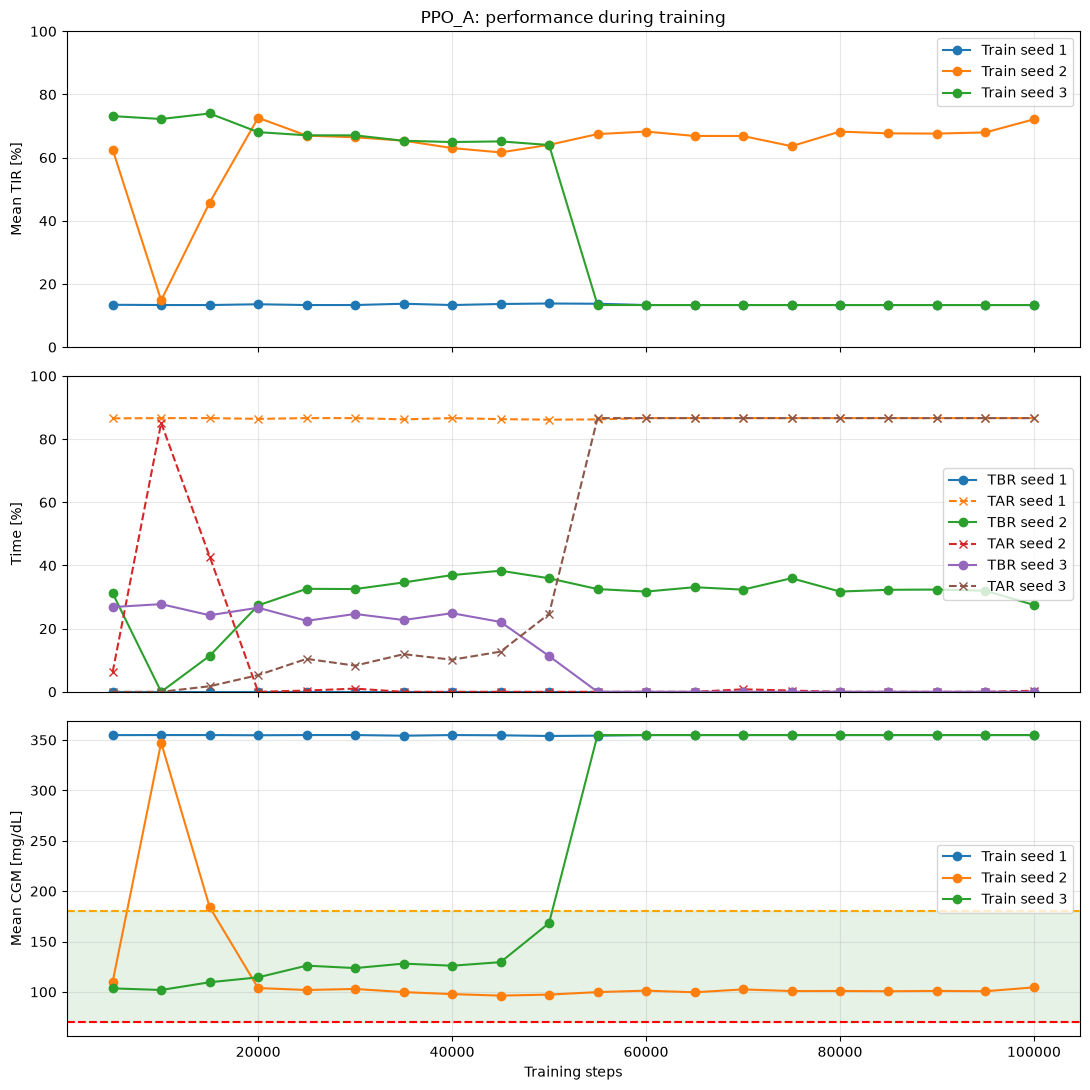

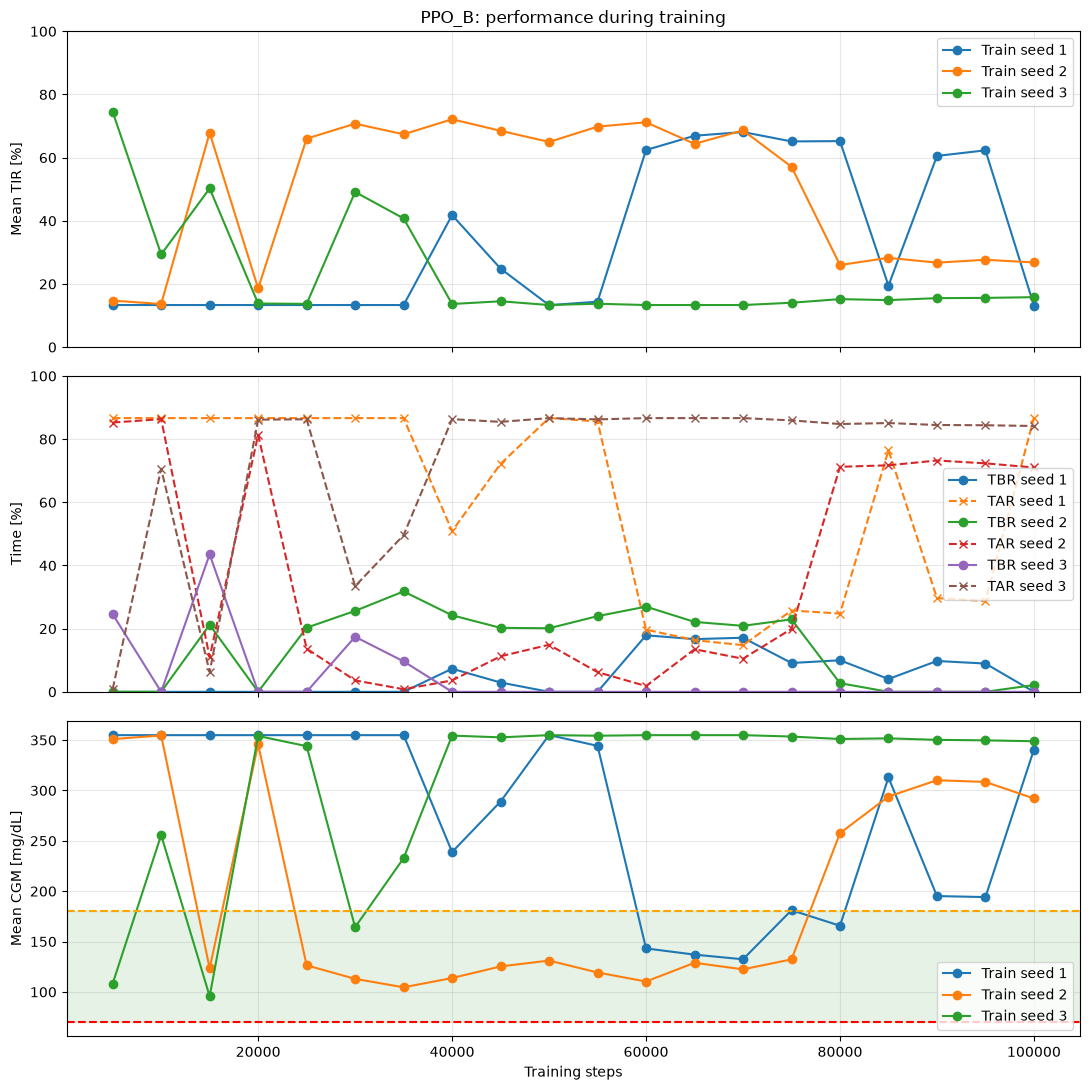

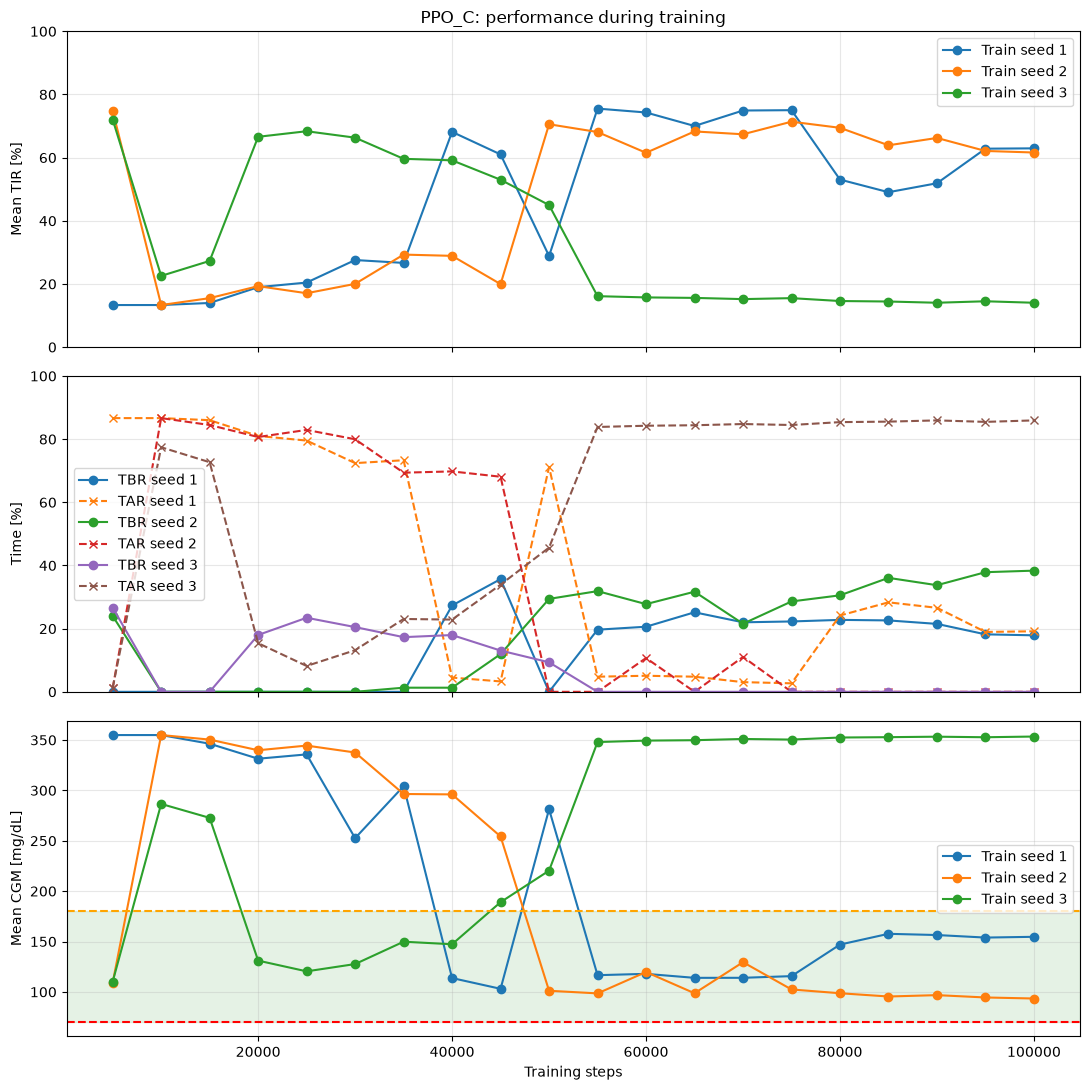

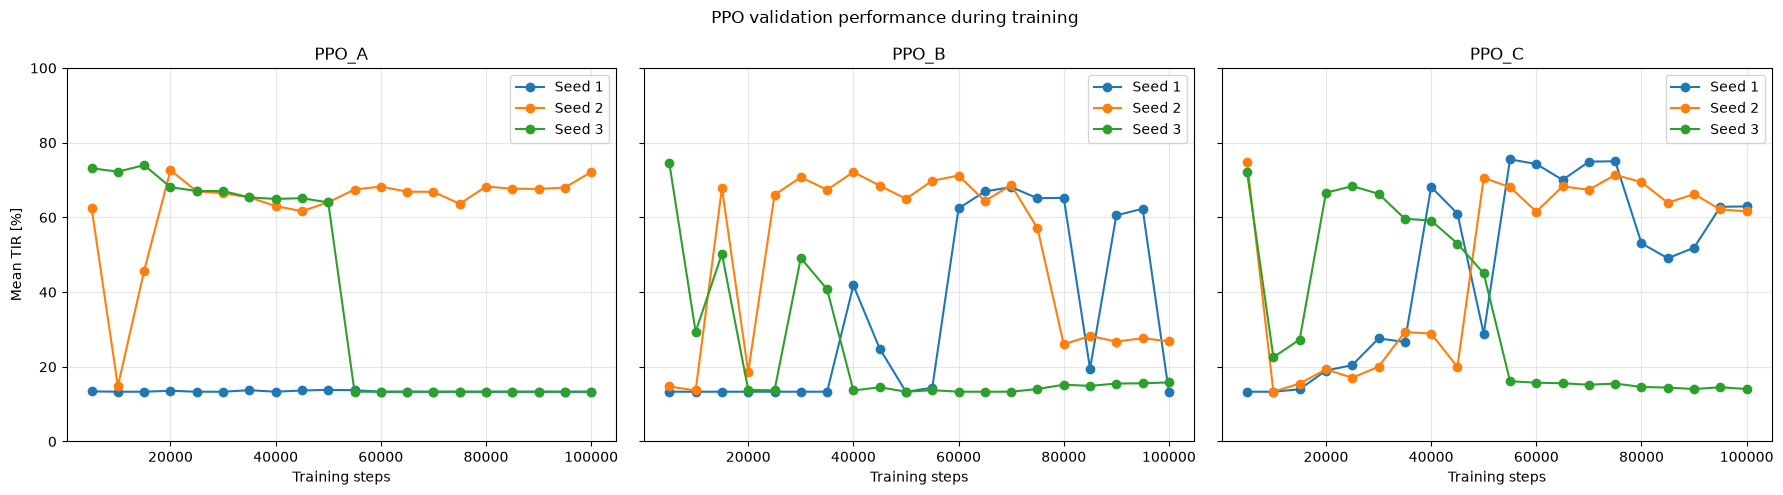

In [43]:
plot_ppo_training_progress(hyperparameter_df)
plot_all_ppo_tir(hyperparameter_df)

  config_id  runs   mean_tir    std_tir  mean_tbr70  mean_tbr54  mean_tar180  \
2     PPO_C   180  43.346175  27.048901   13.469996   10.430424    43.183829   
1     PPO_B   180  35.335550  28.133028    8.072288    6.220445    56.592161   
0     PPO_A   180  39.048872  28.799879   13.939354   10.466775    47.011774   

   mean_tar250     mean_bg  mean_bgstd  mean_reward  termination_rate  \
2    33.728824  220.109970   84.765840    -0.496994          0.777778   
1    43.933649  260.325428   96.324096    -1.435761          0.800000   
0    37.530189  237.157505   85.312695    -1.300489          0.811111   

   mean_number_of_steps  termination_rate_percent  
2            287.027778                 77.777778  
1            327.783333                 80.000000  
0            284.355556                 81.111111  


C:\Users\310271491\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


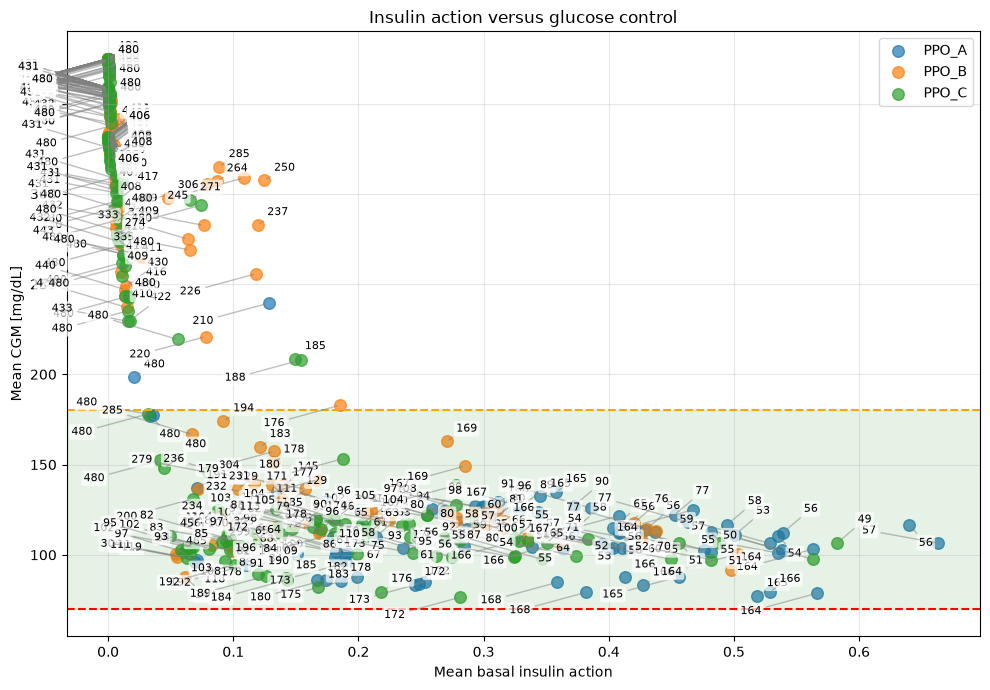

In [44]:
hyperparameter_df = pd.DataFrame(hyperparameter_results)
hyperparameter_df.to_csv(RESULT_DIR / "hyperparameter_results.csv", index=False)

hyperparameter_summary = hyperparameter_df.groupby("config_id", as_index=False).agg(
    runs=("eval_seed", "count"),
    mean_tir=("tir_70_180", "mean"),
    std_tir=("tir_70_180", "std"),
    mean_tbr70=("tbr_below_70", "mean"),
    mean_tbr54=("tbr_below_54", "mean"),
    mean_tar180=("tar_above_180", "mean"),
    mean_tar250=("tar_above_250", "mean"),
    mean_bg=("mean_bg", "mean"),
    mean_bgstd=("std_bg", "mean"),
    mean_reward=("mean_reward", "mean"),
    termination_rate=("terminated_early", "mean"),
    mean_number_of_steps=("number_of_steps", "mean")
)

hyperparameter_summary["termination_rate_percent"] = (100.0 * hyperparameter_summary["termination_rate"])
print(hyperparameter_summary.sort_values(by=["termination_rate", "mean_tbr54", "mean_tbr70", "mean_tir"], ascending=[True, True, True, False],))

# Check the learned policy (e.g. is not basal action = 0)
plot_control_behavior(hyperparameter_df)

## Select PPO Policy

In [ ]:
# -----------------------------------------------------
# Create checkpoint summary
# -----------------------------------------------------

checkpoint_summary = hyperparameter_df.groupby(
    ["config_id", "train_seed", "training_steps"], as_index=False
).agg(
    mean_tir=("tir_70_180", "mean"),
    std_tir=("tir_70_180", "std"),
    mean_tbr70=("tbr_below_70", "mean"),
    mean_tbr54=("tbr_below_54", "mean"),
    mean_tar180=("tar_above_180", "mean"),
    mean_tar250=("tar_above_250", "mean"),
    mean_bg=("mean_bg", "mean"),
    mean_number_of_steps=("number_of_steps", "mean"),
)


# -----------------------------------------------------
# Calculate selection score
# -----------------------------------------------------

checkpoint_summary["selection_score"] = (
    checkpoint_summary["mean_tir"]
    * checkpoint_summary["mean_number_of_steps"]
    / EVAL_STEPS
)


# -----------------------------------------------------
# Select best checkpoint for each PPO configuration
# -----------------------------------------------------

best_per_config = (
    checkpoint_summary.loc[
        checkpoint_summary.groupby("config_id")["selection_score"].idxmax()
    ]
    .sort_values("selection_score", ascending=False)
    .reset_index(drop=True)
)


# -----------------------------------------------------
# Select overall best PPO
# -----------------------------------------------------

best_row = best_per_config.iloc[0]

best_config_id = best_row["config_id"]

best_train_seed = int(best_row["train_seed"])

best_train_steps = int(best_row["training_steps"])


# -----------------------------------------------------
# Find corresponding model file
# -----------------------------------------------------

best_model_path = trained_models_df.loc[
    (trained_models_df["config_id"] == best_config_id)
    & (trained_models_df["train_seed"] == best_train_seed)
    & (trained_models_df["training_steps"] == best_train_steps),
    "model_path",
].iloc[0]


# -----------------------------------------------------
# Print results
# -----------------------------------------------------

print("\nBest checkpoint per configuration:")

print(
    best_per_config[
        [
            "config_id",
            "train_seed",
            "training_steps",
            "mean_tir",
            "std_tir",
            "mean_number_of_steps",
            "selection_score",
        ]
    ]
)

print("\nSelected PPO model")

print("Configuration:", best_config_id)
print("Training seed:", best_train_seed)
print("Training steps:", best_train_steps)
print("Mean TIR:", round(best_row["mean_tir"], 2))
print("TIR SD:", round(best_row["std_tir"], 2))
print("Mean evaluation steps:", round(best_row["mean_number_of_steps"], 1))
print("Selection score:", round(best_row["selection_score"], 2))
print("Model path:", best_model_path)


Best checkpoint per configuration:
  config_id  train_seed  training_steps   mean_tir    std_tir  \
0     PPO_A           2           15000  45.763889   4.255987   
1     PPO_C           3           50000  44.988341  30.853041   
2     PPO_B           3           15000  50.255896   9.684153   

   mean_number_of_steps  selection_score  
0            480.000000        45.763889  
1            411.333333        38.552509  
2            304.000000        31.828734  

Selected PPO model
Configuration: PPO_A
Training seed: 2
Training steps: 15000
Mean TIR: 45.76
TIR SD: 4.26
Mean evaluation steps: 480.0
Selection score: 45.76
Model path: models\checkpoints_PPO_A_seed2\PPO_A_adolescent#002_seed2_15000_steps.zip


## Generalization to other patients

In [71]:
generalization_results = []
generalization_trajectories = {}

for patient_name in TEST_PATIENTS:
    for eval_seed in EVAL_SEEDS:
        print(
            f"Generalization: "
            f"patient={patient_name} | "
            f"eval seed={eval_seed} |"
            f"model={best_model_path} |"
        )

        metrics, trajectory = evaluate_ppo(model_path=best_model_path, patient_name=patient_name, eval_seed=eval_seed, training_steps=best_train_steps, custom_scenario=None)
        generalization_results.append({
            "controller": "PPO",
            "config_id": best_config_id,
            "train_seed": best_train_seed,
            "patient": patient_name,
            "eval_seed": eval_seed,
            "scenario": "standard",
            **metrics
        })

        generalization_trajectories[(patient_name, eval_seed)] = trajectory

Generalization: patient=adolescent#001 | eval seed=101 |model=models\checkpoints_PPO_A_seed2\PPO_A_adolescent#002_seed2_15000_steps.zip |model=2 |training_steps=15000 |
Generalization: patient=adolescent#001 | eval seed=102 |model=models\checkpoints_PPO_A_seed2\PPO_A_adolescent#002_seed2_15000_steps.zip |model=2 |training_steps=15000 |
Generalization: patient=adolescent#001 | eval seed=103 |model=models\checkpoints_PPO_A_seed2\PPO_A_adolescent#002_seed2_15000_steps.zip |model=2 |training_steps=15000 |
Generalization: patient=adolescent#003 | eval seed=101 |model=models\checkpoints_PPO_A_seed2\PPO_A_adolescent#002_seed2_15000_steps.zip |model=2 |training_steps=15000 |
Generalization: patient=adolescent#003 | eval seed=102 |model=models\checkpoints_PPO_A_seed2\PPO_A_adolescent#002_seed2_15000_steps.zip |model=2 |training_steps=15000 |
Generalization: patient=adolescent#003 | eval seed=103 |model=models\checkpoints_PPO_A_seed2\PPO_A_adolescent#002_seed2_15000_steps.zip |model=2 |training_

In [72]:
generalization_df = pd.DataFrame(generalization_results)
generalization_df.to_csv(RESULT_DIR / "generalization_results.csv", index=False)

generalization_summary = (generalization_df.groupby("patient", as_index=False)
    .agg(
        runs=("eval_seed", "count"),
        mean_tir=("tir_70_180", "mean"),
        std_tir=("tir_70_180", "std"),
        mean_tbr70=("tbr_below_70", "mean"),
        mean_tbr54=("tbr_below_54", "mean"),
        mean_tar180=("tar_above_180", "mean"),
        mean_tar250=("tar_above_250", "mean"),
        mean_bg=("mean_bg", "mean"),
        mean_bg_sd=("std_bg", "mean"),
        termination_rate=("terminated_early", "mean")))

print(generalization_summary)

          patient  runs   mean_tir    std_tir  mean_tbr70  mean_tbr54  \
0  adolescent#001     3  65.902778  12.308134   14.930556    6.180556   
1  adolescent#003     3  45.117497  23.496493   54.882503   45.299107   
2       adult#001     3  64.027778   8.842108    0.902778    0.000000   
3       child#001     3  55.230159   3.168576   44.769841   38.206349   

   mean_tar180  mean_tar250     mean_bg  mean_bg_sd  termination_rate  
0    19.166667     2.500000  126.868891   50.099527               0.0  
1     0.000000     0.000000   81.666490   40.620968               1.0  
2    35.069444    12.638889  175.359356   70.497506               0.0  
3     0.000000     0.000000   88.985266   43.973790               1.0  


## High Carb scenario

Voor de beperkte scope gebruiken we één duidelijk maaltijdprofiel:

Tijd	Maaltijd	Koolhydraten08:00	Ontbijt	70 g
10:30	Snack	30 g
13:00	Lunch	90 g
16:00	Snack	30 g
19:00	Diner	110 g

In [73]:
HIGH_CARB_SCHEDULE = [
    (8.0, 70.0),
    (10.5, 30.0),
    (13.0, 90.0),
    (16.0, 30.0),
    (19.0, 110.0)
]

def make_high_carb_scenario():
    return CustomScenario(start_time=datetime(2018, 1, 1, 0, 0, 0), scenario=HIGH_CARB_SCHEDULE.copy())

stress_results = []
stress_trajectories = {}

for patient_name in TEST_PATIENTS:
    for eval_seed in EVAL_SEEDS:

        print(
            f"High-carb stress test: "
            f"patient={patient_name} | "
            f"seed={eval_seed}"
        )

        custom_scenario = make_high_carb_scenario()
        metrics, trajectory = evaluate_ppo(model_path=best_model_path, patient_name=patient_name, eval_seed=eval_seed, training_steps=best_train_steps, custom_scenario=custom_scenario)

        stress_results.append({
            "controller": "PPO",
            "config_id": best_config_id,
            "train_seed": best_train_seed,
            "patient": patient_name,
            "eval_seed": eval_seed,
            "scenario": "high_carb",
            "total_carbohydrates_g": sum(
                amount
                for _, amount in HIGH_CARB_SCHEDULE
            ),
            **metrics
        })

        stress_trajectories[
            (patient_name, eval_seed)
        ] = trajectory

High-carb stress test: patient=adolescent#001 | seed=101
High-carb stress test: patient=adolescent#001 | seed=102
High-carb stress test: patient=adolescent#001 | seed=103
High-carb stress test: patient=adolescent#003 | seed=101
High-carb stress test: patient=adolescent#003 | seed=102
High-carb stress test: patient=adolescent#003 | seed=103
High-carb stress test: patient=adult#001 | seed=101
High-carb stress test: patient=adult#001 | seed=102
High-carb stress test: patient=adult#001 | seed=103
High-carb stress test: patient=child#001 | seed=101
High-carb stress test: patient=child#001 | seed=102
High-carb stress test: patient=child#001 | seed=103


In [74]:
stress_df = pd.DataFrame(stress_results)
stress_df.to_csv(RESULT_DIR / "high_carb_results.csv", index=False)

In [75]:
ppo_test_results = pd.concat([generalization_df, stress_df], ignore_index=True, sort=False)

scenario_summary = (ppo_test_results.groupby(["patient", "scenario"], as_index=False).agg(
        runs=("eval_seed", "count"),
        mean_tir=("tir_70_180", "mean"),
        std_tir=("tir_70_180", "std"),
        mean_tbr70=("tbr_below_70", "mean"),
        mean_tbr54=("tbr_below_54", "mean"),
        mean_tar180=("tar_above_180", "mean"),
        mean_tar250=("tar_above_250", "mean"),
        mean_bg=("mean_bg", "mean"),
        mean_bg_sd=("std_bg", "mean"),
        termination_rate=("terminated_early", "mean")))

print(scenario_summary)

          patient   scenario  runs   mean_tir    std_tir  mean_tbr70  \
0  adolescent#001  high_carb     3  52.222222   6.988748   17.222222   
1  adolescent#001   standard     3  65.902778  12.308134   14.930556   
2  adolescent#003  high_carb     3  57.476478   4.700309   42.523522   
3  adolescent#003   standard     3  45.117497  23.496493   54.882503   
4       adult#001  high_carb     3  41.875000   5.404634    3.472222   
5       adult#001   standard     3  64.027778   8.842108    0.902778   
6       child#001  high_carb     3  55.867347   2.186218   44.132653   
7       child#001   standard     3  55.230159   3.168576   44.769841   

   mean_tbr54  mean_tar180  mean_tar250     mean_bg  mean_bg_sd  \
0    7.777778    30.555556    13.055556  150.797208   76.845290   
1    6.180556    19.166667     2.500000  126.868891   50.099527   
2   36.139113     0.000000     0.000000   91.638584   44.302665   
3   45.299107     0.000000     0.000000   81.666490   40.620968   
4    0.208333   

In [76]:
standard_summary = (
    scenario_summary[scenario_summary["scenario"] == "standard"].drop(columns="scenario").rename(
        columns={
            "mean_tir": "standard_tir",
            "mean_tbr70": "standard_tbr70",
            "mean_tbr54": "standard_tbr54",
            "mean_tar180": "standard_tar180",
            "mean_tar250": "standard_tar250",
            "mean_bg": "standard_mean_bg",
            "mean_bg_sd": "standard_bg_sd",
            "termination_rate": "standard_termination_rate",
        }
    )
)

stress_summary = (
    scenario_summary[scenario_summary["scenario"] == "high_carb"]
    .drop(columns="scenario")
    .rename(
        columns={
            "mean_tir": "stress_tir",
            "mean_tbr70": "stress_tbr70",
            "mean_tbr54": "stress_tbr54",
            "mean_tar180": "stress_tar180",
            "mean_tar250": "stress_tar250",
            "mean_bg": "stress_mean_bg",
            "mean_bg_sd": "stress_bg_sd",
            "termination_rate": "stress_termination_rate",
        }
    )
)

standard_summary = standard_summary[
    [
        "patient",
        "standard_tir",
        "standard_tbr70",
        "standard_tbr54",
        "standard_tar180",
        "standard_tar250",
        "standard_mean_bg",
        "standard_bg_sd",
        "standard_termination_rate",
    ]
]

stress_summary = stress_summary[
    [
        "patient",
        "stress_tir",
        "stress_tbr70",
        "stress_tbr54",
        "stress_tar180",
        "stress_tar250",
        "stress_mean_bg",
        "stress_bg_sd",
        "stress_termination_rate",
    ]
]

In [77]:
scenario_comparison = standard_summary.merge(stress_summary, on="patient", how="inner")
scenario_comparison["delta_tir"] = (scenario_comparison["stress_tir"] - scenario_comparison["standard_tir"])
scenario_comparison["delta_tbr70"] = (scenario_comparison["stress_tbr70"] - scenario_comparison["standard_tbr70"])
scenario_comparison["delta_tbr54"] = (scenario_comparison["stress_tbr54"] - scenario_comparison["standard_tbr54"])
scenario_comparison["delta_tar180"] = (scenario_comparison["stress_tar180"] - scenario_comparison["standard_tar180"])
scenario_comparison["delta_tar250"] = (scenario_comparison["stress_tar250"] - scenario_comparison["standard_tar250"])
scenario_comparison["delta_mean_bg"] = (scenario_comparison["stress_mean_bg"] - scenario_comparison["standard_mean_bg"])
scenario_comparison["delta_bg_sd"] = (scenario_comparison["stress_bg_sd"] - scenario_comparison["standard_bg_sd"])

In [78]:
print(
    scenario_comparison[
        [
            "patient",
            "standard_tir",
            "stress_tir",
            "delta_tir",
            "standard_tbr70",
            "stress_tbr70",
            "delta_tbr70",
            "standard_tar250",
            "stress_tar250",
            "delta_tar250",
        ]
    ]
)

scenario_comparison.to_csv(RESULT_DIR / "standard_vs_high_carb.csv", index=False)

          patient  standard_tir  stress_tir  delta_tir  standard_tbr70  \
0  adolescent#001     65.902778   52.222222 -13.680556       14.930556   
1  adolescent#003     45.117497   57.476478  12.358981       54.882503   
2       adult#001     64.027778   41.875000 -22.152778        0.902778   
3       child#001     55.230159   55.867347   0.637188       44.769841   

   stress_tbr70  delta_tbr70  standard_tar250  stress_tar250  delta_tar250  
0     17.222222     2.291667         2.500000      13.055556     10.555556  
1     42.523522   -12.358981         0.000000       0.000000      0.000000  
2      3.472222     2.569444        12.638889      39.375000     26.736111  
3     44.132653    -0.637188         0.000000       0.000000      0.000000  


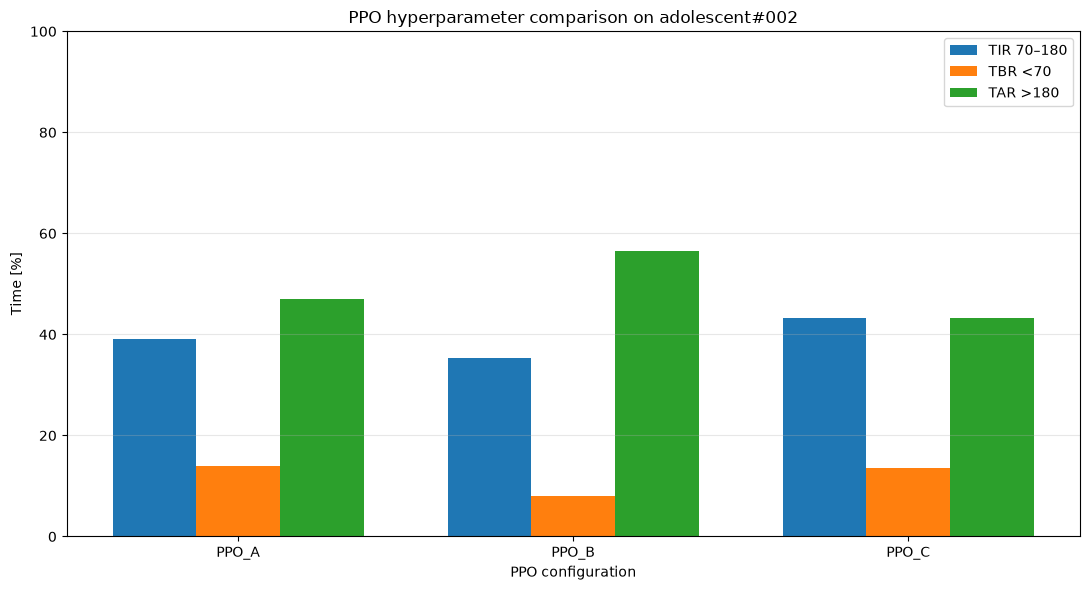

In [79]:
plot_hyperparameter_results(hyperparameter_summary)

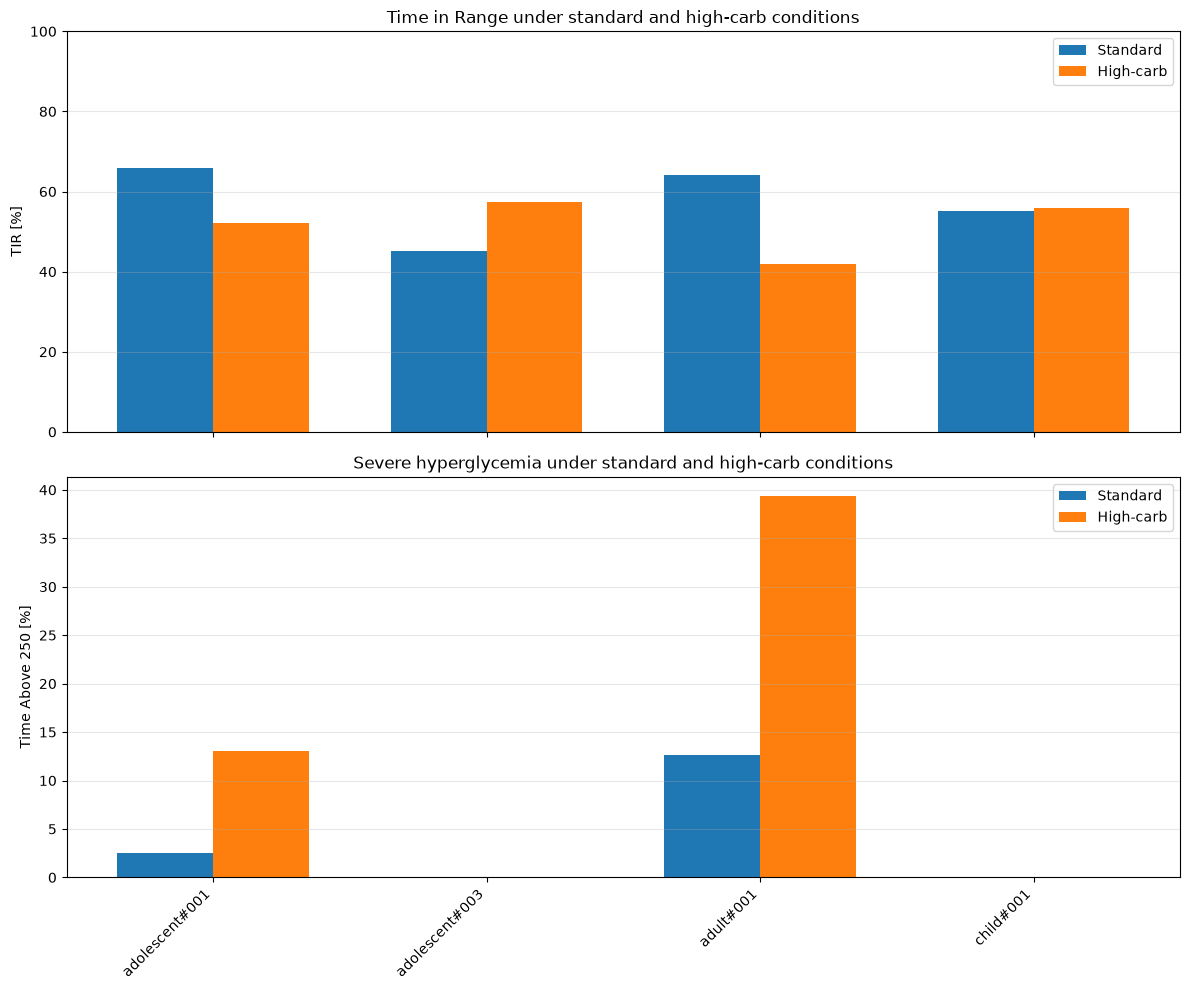

In [80]:
plot_scenario_comparison(scenario_comparison)

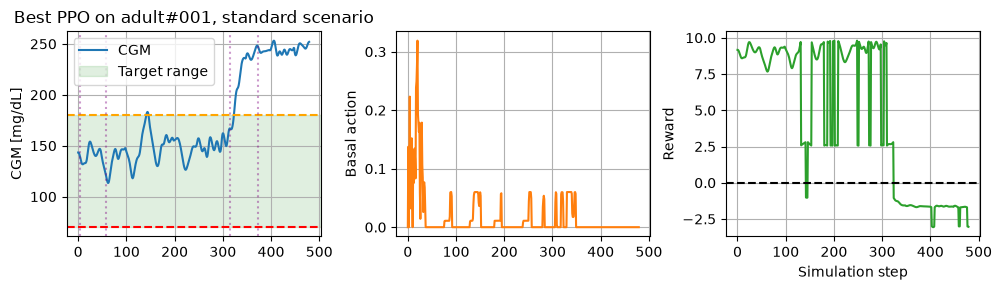

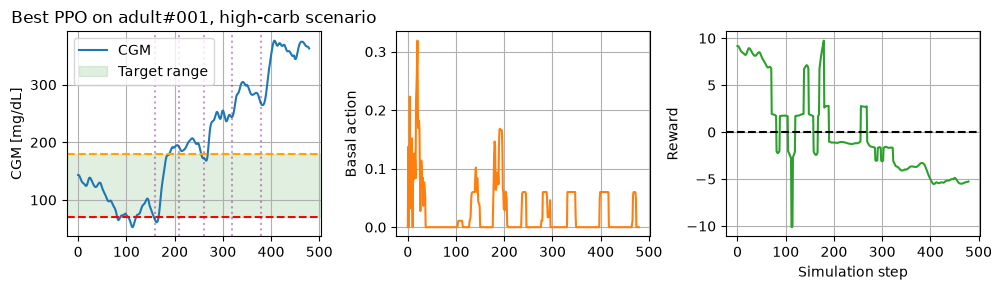

In [81]:
patient = "adult#001"
seed = 101

standard_trajectory = (generalization_trajectories[(patient, seed)])
stress_trajectory = (stress_trajectories[(patient, seed)])


plot_ppo_trajectory(standard_trajectory, title=(f"Best PPO on {patient}, "f"standard scenario"))
plot_ppo_trajectory(stress_trajectory,title=(f"Best PPO on {patient}, "f"high-carb scenario"))

In [82]:
from simglucose.simulation.env import T1DSimEnv
from simglucose.patient.t1dpatient import T1DPatient
from simglucose.sensor.cgm import CGMSensor
from simglucose.actuator.pump import InsulinPump
from simglucose.controller.basal_bolus_ctrller import BBController
from simglucose.simulation.scenario_gen import RandomScenario
from simglucose.simulation.sim_engine import SimObj, sim

In [83]:
def run_bbcontroller(patient_name, seed, high_carb=False):
    start_time = datetime(2018, 1, 1, 0, 0, 0)
    patient = T1DPatient.withName(patient_name, random_init_bg=True, seed=seed)
    sensor = CGMSensor.withName("Dexcom", seed=seed)
    pump = InsulinPump.withName("Insulet")

    if high_carb:
        scenario = CustomScenario(
            start_time=start_time, scenario=HIGH_CARB_SCHEDULE.copy()
        )
    else:
        scenario = RandomScenario(start_time=start_time, seed=seed)

    sim_env = T1DSimEnv(patient=patient, sensor=sensor, pump=pump, scenario=scenario)
    controller = BBController()

    sim_object = SimObj(
        env=sim_env,
        controller=controller,
        sim_time=timedelta(days=1),
        animate=False,
        path=str(RESULT_DIR),
    )

    result = sim(sim_object)
    return result

bb_test = run_bbcontroller(patient_name="adult#001", seed=101, high_carb=False)

print(bb_test.columns)
print(bb_test.head())

Process ID: 23348
Simulation starts ...
Simulation Completed!
Index(['BG', 'CGM', 'CHO', 'insulin', 'LBGI', 'HBGI', 'Risk'], dtype='str')
                             BG         CGM  CHO   insulin  LBGI      HBGI  \
Time                                                                         
2018-01-01 00:00:00  145.840749  189.681898  0.0  0.021125   0.0  2.347692   
2018-01-01 00:03:00  145.064668  185.638278  0.0  0.021125   0.0  2.251902   
2018-01-01 00:06:00  144.107708  182.830142  0.0  0.021125   0.0  2.135862   
2018-01-01 00:09:00  143.361934  180.963375  0.0  0.021125   0.0  2.047049   
2018-01-01 00:12:00  142.776523  179.781782  0.0  0.021125   0.0  1.978345   

                         Risk  
Time                           
2018-01-01 00:00:00  2.347692  
2018-01-01 00:03:00  2.251902  
2018-01-01 00:06:00  2.135862  
2018-01-01 00:09:00  2.047049  
2018-01-01 00:12:00  1.978345  


## BBController Execution

In [84]:
def calculate_bb_metrics(result):
    if "CGM" not in result.columns:
        raise ValueError(
            "Geen CGM-kolom gevonden. "
            f"Beschikbare kolommen: "
            f"{list(result.columns)}")

    glucose = pd.to_numeric(result["CGM"], errors="coerce").dropna().to_numpy()

    if "insulin" in result.columns:
        insulin = (pd.to_numeric(result["insulin"], errors="coerce").fillna(0.0).to_numpy())
    else:
        insulin = np.zeros(len(glucose))

    common_length = min(len(glucose), len(insulin))

    return calculate_metrics(
        glucose=glucose[:common_length],
        insulin=insulin[:common_length],
        rewards=np.zeros(common_length),
        terminated_early=False,)

In [85]:
bb_results = []

for patient_name in TEST_PATIENTS:
    for eval_seed in EVAL_SEEDS:
        for high_carb in [False, True]:
            scenario_name = "high_carb" if high_carb else "standard"

            print(
                f"BBController | "
                f"patient={patient_name} | "
                f"scenario={scenario_name} | "
                f"seed={eval_seed}"
            )

            result = run_bbcontroller(patient_name=patient_name, seed=eval_seed, high_carb=high_carb)
            metrics = calculate_bb_metrics(result)

            bb_results.append({
                    "controller": "BBController",
                    "patient": patient_name,
                    "eval_seed": eval_seed,
                    "scenario": scenario_name,
                    **metrics,})

BBController | patient=adolescent#001 | scenario=standard | seed=101
Process ID: 23348
Simulation starts ...
Simulation Completed!
BBController | patient=adolescent#001 | scenario=high_carb | seed=101
Process ID: 23348
Simulation starts ...
Simulation Completed!
BBController | patient=adolescent#001 | scenario=standard | seed=102
Process ID: 23348
Simulation starts ...
Simulation Completed!
BBController | patient=adolescent#001 | scenario=high_carb | seed=102
Process ID: 23348
Simulation starts ...
Simulation Completed!
BBController | patient=adolescent#001 | scenario=standard | seed=103
Process ID: 23348
Simulation starts ...
Simulation Completed!
BBController | patient=adolescent#001 | scenario=high_carb | seed=103
Process ID: 23348
Simulation starts ...
Simulation Completed!
BBController | patient=adolescent#003 | scenario=standard | seed=101
Process ID: 23348
Simulation starts ...
Simulation Completed!
BBController | patient=adolescent#003 | scenario=high_carb | seed=101
Process ID

In [86]:
bb_results_df = pd.DataFrame(bb_results)

bb_results_df.to_csv(RESULT_DIR / "bbcontroller_results.csv", index=False)

In [87]:
ppo_results_for_comparison = ppo_test_results[
    ["controller",
        "patient",
        "eval_seed",
        "scenario",
        "tir_70_180",
        "tbr_below_70",
        "tbr_below_54",
        "tar_above_180",
        "tar_above_250",
        "mean_bg",
        "std_bg",
        "terminated_early",]]

bb_results_for_comparison = bb_results_df[
    [
        "controller",
        "patient",
        "eval_seed",
        "scenario",
        "tir_70_180",
        "tbr_below_70",
        "tbr_below_54",
        "tar_above_180",
        "tar_above_250",
        "mean_bg",
        "std_bg",
        "terminated_early",
    ]
]

In [88]:
all_results = pd.concat([ppo_results_for_comparison, bb_results_for_comparison], ignore_index=True)

final_summary = all_results.groupby(
    ["controller", "scenario", "patient"], as_index=False
).agg(
    runs=("eval_seed", "count"),
    mean_tir=("tir_70_180", "mean"),
    std_tir=("tir_70_180", "std"),
    mean_tbr70=("tbr_below_70", "mean"),
    mean_tbr54=("tbr_below_54", "mean"),
    mean_tar180=("tar_above_180", "mean"),
    mean_tar250=("tar_above_250", "mean"),
    mean_bg=("mean_bg", "mean"),
    mean_bg_sd=("std_bg", "mean"),
    termination_rate=("terminated_early", "mean"),
)

final_summary["termination_rate_percent"] = 100.0 * final_summary["termination_rate"]

final_summary.to_csv(RESULT_DIR / "final_summary.csv", index=False)

print(final_summary)

      controller   scenario         patient  runs   mean_tir    std_tir  \
0   BBController  high_carb  adolescent#001     3  95.287595   4.086354   
1   BBController  high_carb  adolescent#003     3  81.427581   4.877169   
2   BBController  high_carb       adult#001     3  85.377685   5.660590   
3   BBController  high_carb       child#001     3  74.497574   2.299468   
4   BBController   standard  adolescent#001     3  96.534997   3.175728   
5   BBController   standard  adolescent#003     3  81.288981   7.114320   
6   BBController   standard       adult#001     3  87.110187   8.166536   
7   BBController   standard       child#001     3  74.012474   7.068607   
8            PPO  high_carb  adolescent#001     3  52.222222   6.988748   
9            PPO  high_carb  adolescent#003     3  57.476478   4.700309   
10           PPO  high_carb       adult#001     3  41.875000   5.404634   
11           PPO  high_carb       child#001     3  55.867347   2.186218   
12           PPO   standa

In [89]:
tir_comparison = final_summary.pivot_table(
    index=["scenario", "patient"], columns="controller", values="mean_tir"
).reset_index()

if "PPO" in tir_comparison.columns and "BBController" in tir_comparison.columns:
    tir_comparison["delta_tir_ppo_minus_bb"] = (
        tir_comparison["PPO"] - tir_comparison["BBController"]
    )

print(tir_comparison)

controller   scenario         patient  BBController        PPO  \
0           high_carb  adolescent#001     95.287595  52.222222   
1           high_carb  adolescent#003     81.427581  57.476478   
2           high_carb       adult#001     85.377685  41.875000   
3           high_carb       child#001     74.497574  55.867347   
4            standard  adolescent#001     96.534997  65.902778   
5            standard  adolescent#003     81.288981  45.117497   
6            standard       adult#001     87.110187  64.027778   
7            standard       child#001     74.012474  55.230159   

controller  delta_tir_ppo_minus_bb  
0                       -43.065373  
1                       -23.951103  
2                       -43.502685  
3                       -18.630228  
4                       -30.632219  
5                       -36.171484  
6                       -23.082409  
7                       -18.782315  


## Final Summary

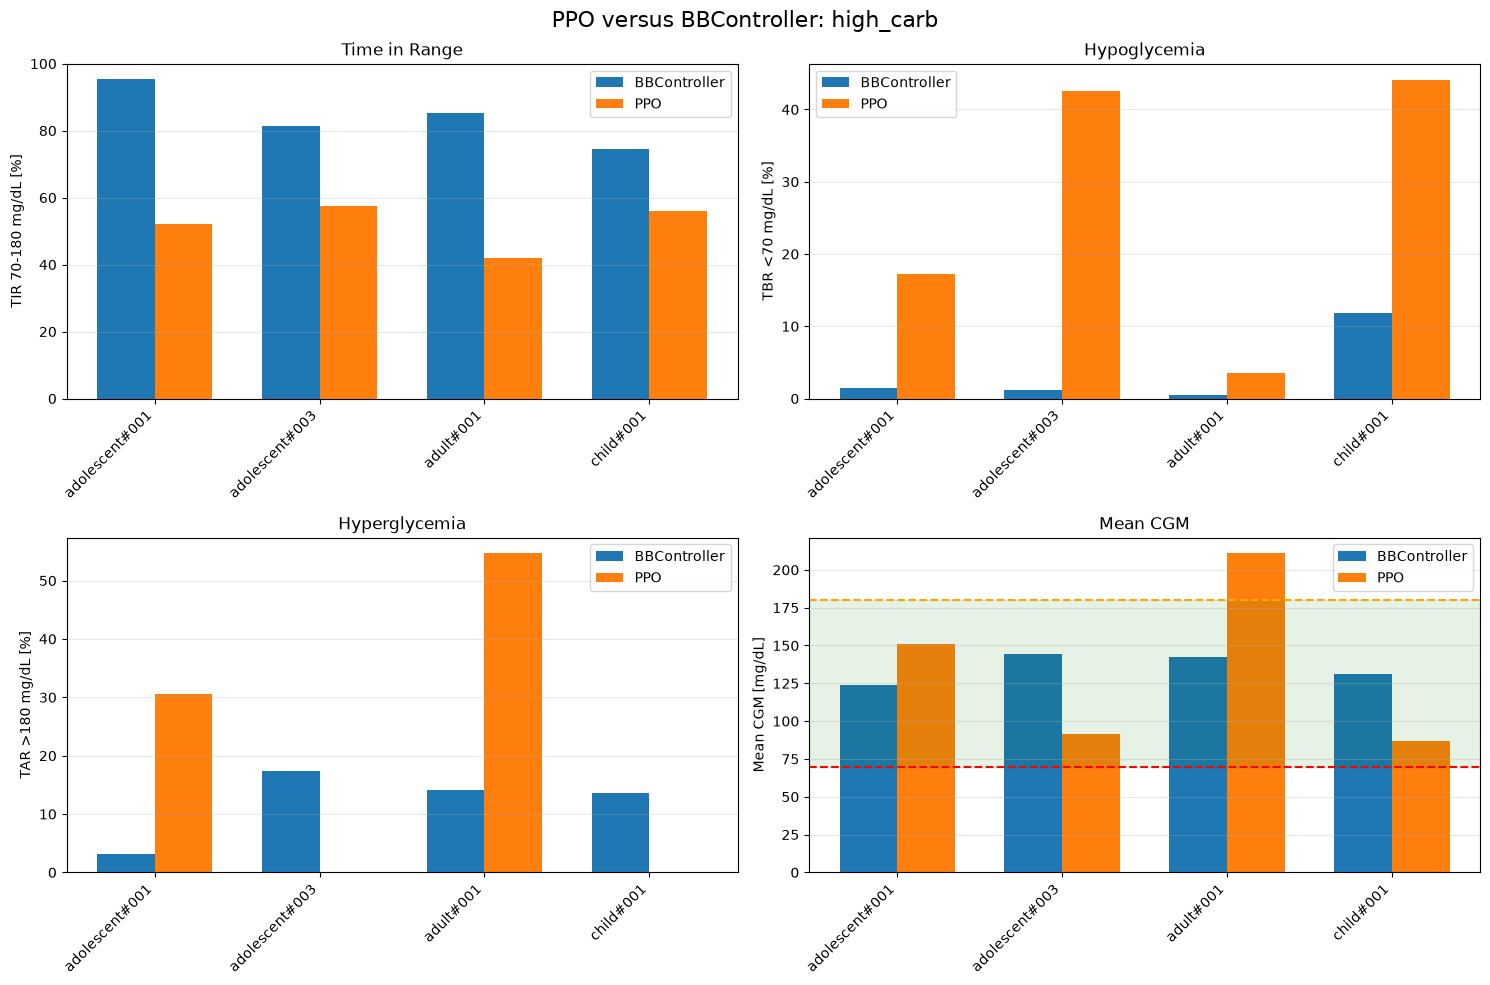

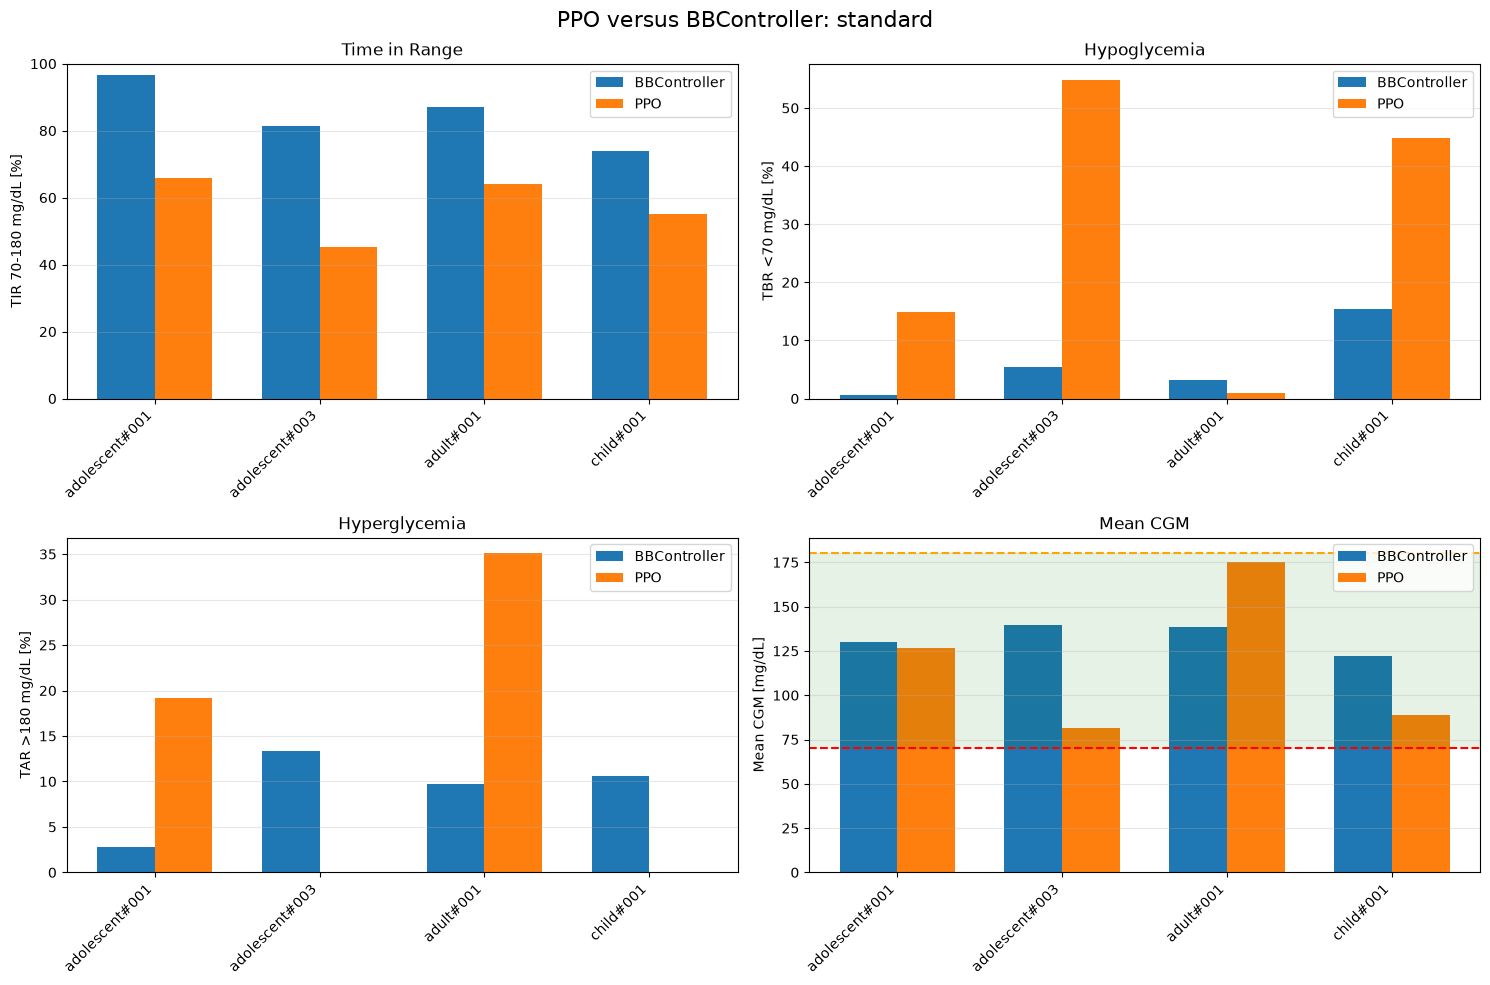

In [90]:
plot_final_summary(final_summary)